# Data Loading

In [1]:
!pip install pandas 
!pip install geopandas
!pip install seaborn
!pip install re
!pip install matplotlib
!pip install numpy
!pip install BeautifulSoup
!pip install requests 

ERROR: Could not find a version that satisfies the requirement re (from versions: none)
ERROR: No matching distribution found for re
  Using cached BeautifulSoup-3.2.2.tar.gz (32 kB)
  Preparing metadata (setup.py) ... error
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [7 lines of output]
      Traceback (most recent call last):
        File "<string>", line 2, in <module>
        File "<pip-setuptools-caller>", line 34, in <module>
        File "/private/var/folders/6z/01n3y92d1mg2ftw2s_f2lv5w0000gn/T/pip-install-wkjils__/beautifulsoup_822fce54db314096a35c50d68f04fad7/setup.py", line 3
          "You're trying to run a very old release of Beautiful Soup under Python 3. This will not work."<>"Please use Beautiful Soup 4, available through the pip package 'beautifulsoup4'."
                                                                                                         ^^
      SyntaxError: invalid syntax


In [2]:
# Packages
from pathlib import Path
import pandas as pd 
import geopandas as gpd
import seaborn as sns
import re
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from scipy import stats
from bs4 import BeautifulSoup
import requests

In [3]:
# paths 
project_fldr = Path.cwd().parent
raw_fldr = project_fldr /'Data'/'unprocessed' 
processed_fldr = project_fldr /'Data'/'processed'

In [5]:
# Importing the data
pest_use = pd.read_csv("https://www.sciencebase.gov/catalog/file/get/5e95c12282ce172707f2524e?name=EPest_county_estimates_2013_2017_v2.txt", sep="\t")
site_info = pd.read_csv(raw_fldr/'site_info.csv')
pest_water= pd.read_csv(raw_fldr/'pest_water.csv')

# Data Cleaning

### Column Cleaning

In [6]:
#Pesticide Use Data 
pest_use = pest_use.loc[:,['COMPOUND', 'YEAR', 'STATE_FIPS_CODE', 'COUNTY_FIPS_CODE', 'EPEST_HIGH_KG']]

In [7]:
#Water Pesticide Concentration Data 
pest_water = pest_water.loc[:,['Pesticide_Site', 'Pesticide_Name','Water_Year', 'Result_Value_ug_L']]

In [8]:
#Site Info 
site_info = site_info.loc[:,['Location_Identifier', 'station_nm','state_cd', 'huc_cd',	'Drainage_area_km2','dec_lat_va','dec_long_va']]

### Fixing Column Types

In [9]:
# Pesticide Use Compounds 
pest_use['Year'] = pd.to_datetime(pest_use['YEAR'], format='%Y')
pest_use["STATE_FIPS_CODE"] = pest_use["STATE_FIPS_CODE"].astype("category")
pest_use["COUNTY_FIPS_CODE"] = pest_use["COUNTY_FIPS_CODE"].astype("category")

In [10]:
# Water Pesticide Data 
pest_water['Year'] = pd.to_datetime(pest_water['Water_Year'], format='%Y')

In [11]:
# Site Information 
site_info["huc_cd"] = site_info["huc_cd"].astype("category")
site_info["state_cd"] = site_info["state_cd"].astype("category")

### Name Standardizing

In [12]:
# making function to strip names so that difference in capitlization, spacing, and , 
# will not cause names to not match.  
def clean_name(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

In [13]:
# Running Data Through Function
pest_use["name_clean"]   = pest_use["COMPOUND"].map(clean_name)
pest_water["name_clean"] = pest_water["Pesticide_Name"].map(clean_name)

In [14]:
#Taking out USGS from Location Identity to help match with Water data 
site_info["site_id"] = site_info["Location_Identifier"].str.replace("USGS-", "")
site_info.head()

,Location_Identifier,station_nm,state_cd,huc_cd,Drainage_area_km2,dec_lat_va,dec_long_va,site_id
0,USGS-06713500,"CHERRY CREEK AT DENVER, CO.",8,10190003,1062.0,39.742487,-104.999982,06713500
1,USGS-06754000,"SOUTH PLATTE RIVER NEAR KERSEY, CO",8,10190003,25022.0,40.411925,-104.562737,06754000
2,USGS-06805500,"Platte River at Louisville, Nebr",31,10200202,221107.0,41.014978,-96.157500,06805500
3,USGS-06329500,Yellowstone River near Sidney MT,30,10100004,178966.0,47.677414,-104.155411,06329500
4,USGS-07144100,"L ARKANSAS R NR SEDGWICK, KS",20,11030012,3209.0,37.883067,-97.424486,07144100


In [15]:
#Get water pesticide location without starting name 
pest_water["site_id"] = pest_water["Pesticide_Site"].str.split("_").str[1]
pest_water.head()

,Pesticide_Site,Pesticide_Name,Water_Year,Result_Value_ug_L,Year,name_clean,site_id
0,"1H-1,2,4-Triazole_01184000","1H-1,2,4-Triazole",2013,0.0262,2013-01-01,1h124triazole,01184000
1,"1H-1,2,4-Triazole_01184000","1H-1,2,4-Triazole",2013,0.0486,2013-01-01,1h124triazole,01184000
2,"1H-1,2,4-Triazole_01184000","1H-1,2,4-Triazole",2013,0.0391,2013-01-01,1h124triazole,01184000
3,"1H-1,2,4-Triazole_01184000","1H-1,2,4-Triazole",2013,0.0220,2013-01-01,1h124triazole,01184000
4,"1H-1,2,4-Triazole_01184000","1H-1,2,4-Triazole",2013,0.0803,2013-01-01,1h124triazole,01184000


# Joining Data 

### Joining Site Location Data with Water Samples

In [16]:
#Left Join using pest_water using site_id column 
pest_water_loc = (
    pest_water
    .join(
        site_info.set_index('site_id'),
        on='site_id',
        how='left'
    )
    .drop(columns=['Pesticide_Site', 'Location_Identifier'])
)
pest_water_loc.head()

,Pesticide_Name,Water_Year,Result_Value_ug_L,Year,name_clean,site_id,station_nm,state_cd,huc_cd,Drainage_area_km2,dec_lat_va,dec_long_va
0,"1H-1,2,4-Triazole",2013,0.0262,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367
1,"1H-1,2,4-Triazole",2013,0.0486,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367
2,"1H-1,2,4-Triazole",2013,0.0391,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367
3,"1H-1,2,4-Triazole",2013,0.0220,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367
4,"1H-1,2,4-Triazole",2013,0.0803,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367


In [17]:
# Site join check
print('Water rows before site join:', len(pest_water))
print('Water rows after site join:', len(pest_water_loc))
print('Rows with no matching site:', pest_water_loc['station_nm'].isna().sum())

Water rows before site join: 955728
Water rows after site join: 955728
Rows with no matching site: 0


### Getting Counties from Lat Long Values

In [18]:
# Load a file of county boundries in 2017
counties = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2017/shp/cb_2017_us_county_500k.zip"
)[['GEOID', 'STATEFP', 'COUNTYFP', 'NAME', 'geometry']]

# Plots points and then sees which county falls into and adds column with FIPS code falls into 
sites_gdf = gpd.GeoDataFrame(
    pest_water_loc,
    geometry=gpd.points_from_xy(pest_water_loc['dec_long_va'], pest_water_loc['dec_lat_va']),
    crs="EPSG:4269"  
).to_crs(counties.crs)

#Joins dataset back with pest_water_loc
pest_water_loc = (
    gpd.sjoin(sites_gdf, counties, how='left', predicate='within')
    .rename(columns={'GEOID': 'county_fips', 'NAME': 'county_name'})
    .drop(columns=['STATEFP','COUNTYFP',"index_right"])
)

pest_water_loc.head()

,Pesticide_Name,Water_Year,Result_Value_ug_L,Year,name_clean,site_id,station_nm,state_cd,huc_cd,Drainage_area_km2,dec_lat_va,dec_long_va,geometry,county_fips,county_name
0,"1H-1,2,4-Triazole",2013,0.0262,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford
1,"1H-1,2,4-Triazole",2013,0.0486,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford
2,"1H-1,2,4-Triazole",2013,0.0391,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford
3,"1H-1,2,4-Triazole",2013,0.0220,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford
4,"1H-1,2,4-Triazole",2013,0.0803,2013-01-01,1h124triazole,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford


In [19]:
# County spatial join check
print('Rows after county join:', len(pest_water_loc))
print('Rows with no county match:', pest_water_loc['county_fips'].isna().sum())
print('Counties with monitoring sites:', pest_water_loc['county_fips'].nunique())

Rows after county join: 955728
Rows with no county match: 0
Counties with monitoring sites: 76


### Joining Pesticide Use and Water Sample Data 

In [20]:
# Ensures same type so that can properly join 
pest_use['STATE_FIPS_CODE']=pest_use['STATE_FIPS_CODE'].astype(str)
pest_use['COUNTY_FIPS_CODE']=pest_use['COUNTY_FIPS_CODE'].astype(str)

In [21]:
pest_use['county_fips'] = (
    pest_use['STATE_FIPS_CODE'].astype(int) * 1000
    + pest_use['COUNTY_FIPS_CODE'].astype(int)
).astype('category')

In [22]:
def add_zero(code):
    code = str(code)
    if len(code) < 5:
        code = '0' + code
    return code

pest_use['county_fips'] = pest_use['county_fips'].astype(int).apply(add_zero)

In [23]:
pest_water_loc['county_fips'] = pest_water_loc['county_fips'].astype(str)
pest_use['county_fips'] = pest_use['county_fips'].astype(str)

In [24]:
#Join of all data
pest_water_use = (
    pest_water_loc
    .join(
        pest_use.set_index(['county_fips', 'Year', 'name_clean']),
        on=['county_fips', 'Year', 'name_clean'],
        how='inner',
        rsuffix='_use'
    )
)

pest_water_use.head()

,Pesticide_Name,Water_Year,Result_Value_ug_L,Year,name_clean,site_id,station_nm,state_cd,huc_cd,Drainage_area_km2,dec_lat_va,dec_long_va,geometry,county_fips,county_name,COMPOUND,YEAR,STATE_FIPS_CODE,COUNTY_FIPS_CODE,EPEST_HIGH_KG
5250,"2,4-D",2013,0.062,2013-01-01,24d,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford,"2,4-D",2013,9,3,362.3
5251,"2,4-D",2013,0.062,2013-01-01,24d,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford,"2,4-D",2013,9,3,362.3
5252,"2,4-D",2013,0.062,2013-01-01,24d,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford,"2,4-D",2013,9,3,362.3
5253,"2,4-D",2013,0.062,2013-01-01,24d,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford,"2,4-D",2013,9,3,362.3
5254,"2,4-D",2013,0.062,2013-01-01,24d,01184000,"CONNECTICUT RIVER AT THOMPSONVILLE, CT",9,1080205,25019.0,41.987319,-72.605367,POINT (-72.60537 41.98732),09003,Hartford,"2,4-D",2013,9,3,362.3


In [25]:
# Join Check
print('Rows after big join:', len(pest_water_use))
print('Rows with no match:', pest_water_use['county_fips'].isna().sum())
print('Counties with monitoring sites:', pest_water_use['county_fips'].nunique())

Rows after big join: 176787
Rows with no match: 0
Counties with monitoring sites: 74


In [26]:
# Saving File 
pest_water_use.to_csv(Path.home() / 'Downloads' / 'pest_water_use_processed.csv', index=False)

#move to processed folder after, file size is large

### Avg Join

In [27]:
#avg pest use and water concentration 
# aggregated by site so that there is only 1 value a year
pest_water_use_avg = (pest_water_use
    .groupby(['Pesticide_Name', 'Water_Year','site_id'])
    .agg(
        mean_concentration_water=('Result_Value_ug_L', 'mean'),
        mean_pesticide_use=('EPEST_HIGH_KG', 'mean')
    )
    .reset_index()
)
pest_water_use_avg.head()


,Pesticide_Name,Water_Year,site_id,mean_concentration_water,mean_pesticide_use
0,"2,4-D",2013,01184000,0.128033,362.3
1,"2,4-D",2013,01209710,0.075609,80.7
2,"2,4-D",2013,01349150,0.063613,515.2
3,"2,4-D",2013,01372043,0.052507,742.3
4,"2,4-D",2013,01463500,0.061000,419.3


### Cloropleth map Join

In [28]:
county_use = (
    pest_water_use
    .drop_duplicates(['county_fips', 'COMPOUND', 'Water_Year'])
    .groupby(['county_fips', 'Water_Year'])['EPEST_HIGH_KG'].sum()
    .groupby('county_fips').mean()
    .rename('pest_kg')
)
county_use.head()

county_fips
01023     3951.20
01097    24901.05
01099    20967.90
04005     7759.30
05119    32040.06
Name: pest_kg, dtype: float64

# Plots

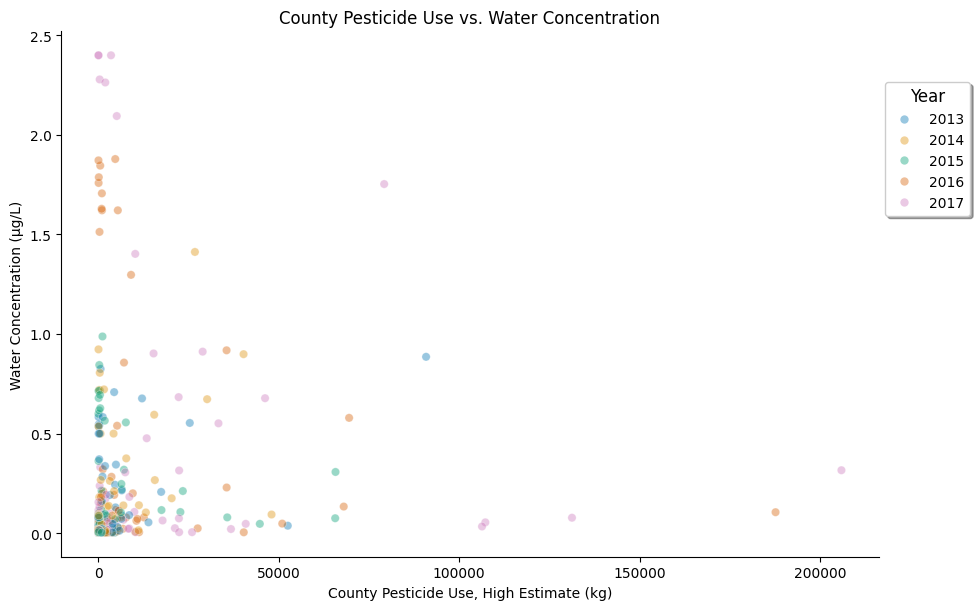

In [29]:
# nonlogged plot 
g = sns.relplot(
    data=pest_water_use_avg.sample(1000, random_state=1),
    x='mean_pesticide_use',
    y='mean_concentration_water',
    hue='Water_Year',
    kind='scatter',
    alpha=0.4,
    palette='colorblind',
    height=6,
    aspect=1.5
).set(
    title='County Pesticide Use vs. Water Concentration',
    xlabel='County Pesticide Use, High Estimate (kg)',
    ylabel='Water Concentration (µg/L)',
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor=(1, 0.9),
    title='Year',
    title_fontsize=12,
    shadow=True,
    frameon=True
);

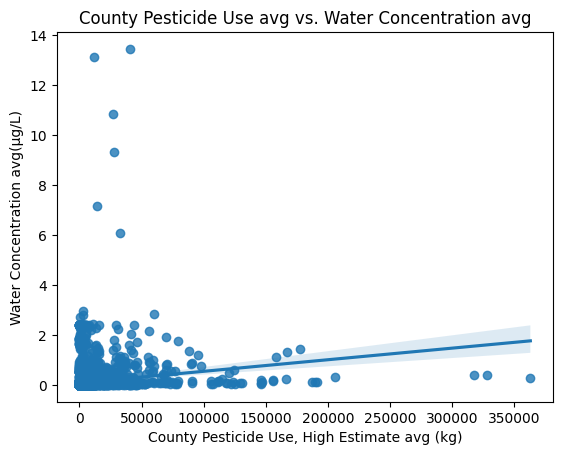

In [30]:
#regression line non logged data
ax = sns.regplot(
    data=pest_water_use_avg,
    x='mean_pesticide_use',
    y='mean_concentration_water',
)
ax.set(
    title='County Pesticide Use avg vs. Water Concentration avg',
    xlabel='County Pesticide Use, High Estimate avg (kg)',
    ylabel='Water Concentration avg(µg/L)',
);

In [31]:
# regression values
reg_df_nolog = (
    pest_water_use_avg[['mean_pesticide_use', 'mean_concentration_water']]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

result_nolog = stats.linregress(reg_df_nolog['mean_pesticide_use'], reg_df_nolog['mean_concentration_water'])

pd.Series({
    'slope': result_nolog.slope,
    'intercept': result_nolog.intercept,
    'R²': result_nolog.rvalue**2,
    'p-value': result_nolog.pvalue,
}).round(10)

slope        0.000005
intercept    0.082335
R²           0.020283
p-value      0.000000
dtype: float64

### Logging Avg Data

In [32]:
pest_water_use_avg['log_mean_pesticide_use'] = np.log10(pest_water_use_avg['mean_pesticide_use'].dropna())
pest_water_use_avg['log_mean_concentration_water'] = np.log10(pest_water_use_avg['mean_concentration_water'].dropna())
pest_water_use_avg.head()

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Pesticide_Name,Water_Year,site_id,mean_concentration_water,mean_pesticide_use,log_mean_pesticide_use,log_mean_concentration_water
0,"2,4-D",2013,01184000,0.128033,362.3,2.559068,-0.892677
1,"2,4-D",2013,01209710,0.075609,80.7,1.906874,-1.121428
2,"2,4-D",2013,01349150,0.063613,515.2,2.711976,-1.196458
3,"2,4-D",2013,01372043,0.052507,742.3,2.870579,-1.279782
4,"2,4-D",2013,01463500,0.061000,419.3,2.622525,-1.214670


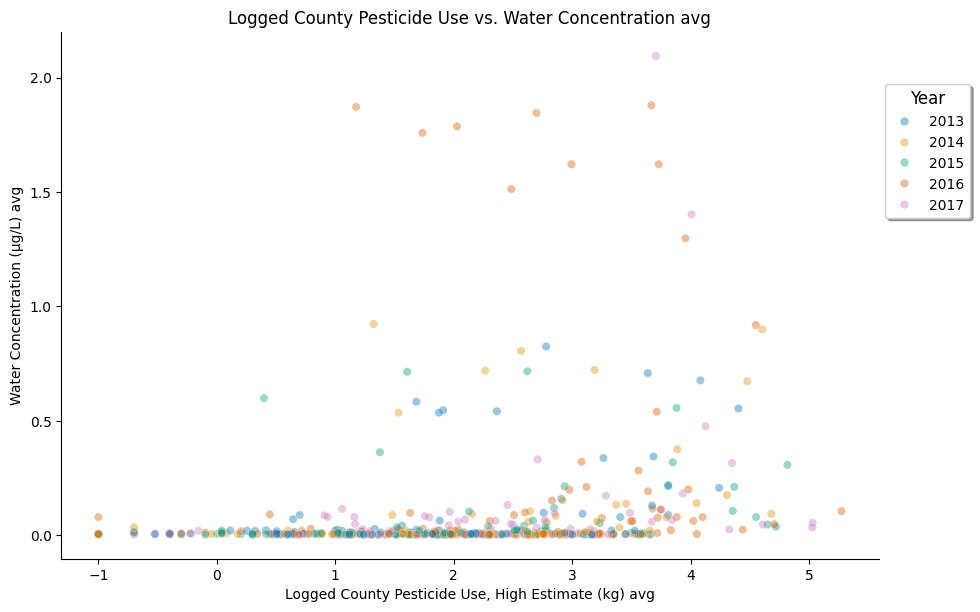

In [33]:
#only pest data logged 
plot_log_avg = pest_water_use_avg[
    np.isfinite(pest_water_use_avg['log_mean_pesticide_use'].notnull()) & np.isfinite(pest_water_use_avg['mean_concentration_water'].notnull())
].sample(500, random_state=1)

g = sns.relplot(
    data=plot_log_avg,
    x='log_mean_pesticide_use',
    y='mean_concentration_water',
    hue='Water_Year',
    kind='scatter',
    alpha=0.4,
    palette='colorblind',
    height=6,
    aspect=1.5
).set(
    title='Logged County Pesticide Use vs. Water Concentration avg',
    xlabel='Logged County Pesticide Use, High Estimate (kg) avg',
    ylabel='Water Concentration (µg/L) avg',
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor=(1, 0.9),
    title='Year',
    title_fontsize=12,
    shadow=True,
    frameon=True
);

### Loggedlogged Data

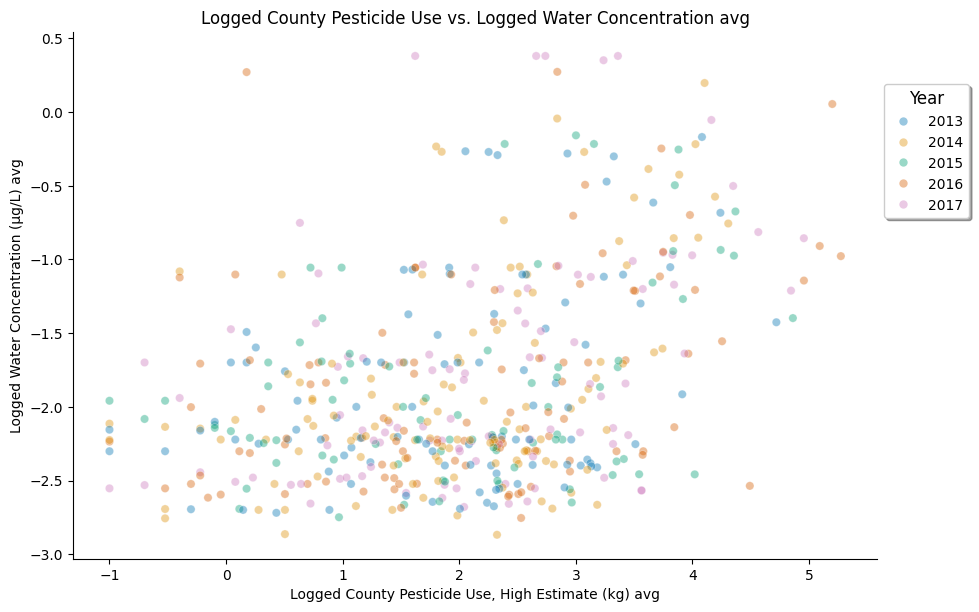

In [34]:
#loggedlogged
plot_loglog_avg = pest_water_use_avg[
    np.isfinite(pest_water_use_avg['log_mean_pesticide_use'])
    & np.isfinite(pest_water_use_avg['log_mean_concentration_water'])
].sample(500, random_state=1)

g = sns.relplot(
    data=plot_loglog_avg,
    x='log_mean_pesticide_use',
    y='log_mean_concentration_water',
    hue='Water_Year',
    kind='scatter',
    alpha=0.4,
    palette='colorblind',
    height=6,
    aspect=1.5
).set(
    title='Logged County Pesticide Use vs. Logged Water Concentration avg',
    xlabel='Logged County Pesticide Use, High Estimate (kg) avg',
    ylabel='Logged Water Concentration (µg/L) avg'
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor=(1, 0.9),
    title='Year',
    title_fontsize=12,
    shadow=True,
    frameon=True
);

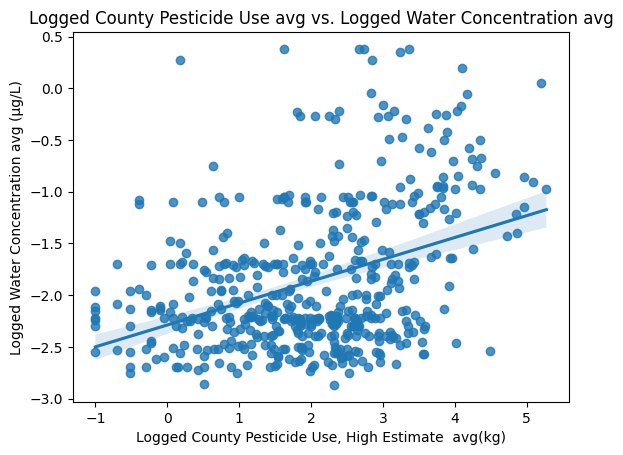

In [35]:
#loggedlogged regression line
ax = sns.regplot(
    data=plot_loglog_avg,
    x='log_mean_pesticide_use',
    y='log_mean_concentration_water',
)
ax.set(
    title='Logged County Pesticide Use avg vs. Logged Water Concentration avg',
    xlabel='Logged County Pesticide Use, High Estimate  avg(kg)',
    ylabel='Logged Water Concentration avg (µg/L)',
);

In [36]:
print(np.isinf(pest_water_use_avg['log_mean_pesticide_use']).sum())
print(np.isinf(pest_water_use_avg['log_mean_concentration_water']).sum())
reg_df_avg = (
    pest_water_use_avg[['log_mean_pesticide_use', 'log_mean_concentration_water']]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

143
0


In [37]:
result = stats.linregress(reg_df_avg['log_mean_pesticide_use'], reg_df_avg['log_mean_concentration_water'])

pd.Series({
    'slope': result.slope,
    'intercept': result.intercept,
    'R²': result.rvalue**2,
    'p-value': result.pvalue,
}).round(5)

slope        0.21109
intercept   -2.28161
R²           0.13747
p-value      0.00000
dtype: float64

For the plotted estimated pesticide use (kg) by measured pesticide concentrations (μg/L) in surface waters, initially just the raw values were plotted. It was then reproduced with the estimated pesticide use on a log scale, and finally reproduced the plot with both the pesticide usage and contaminant concentrations on a log scale. This final transformation revealed a more apparent trend in the data, suggesting that pesticide contaminant concentrations increase with pesticide usage.

A linear regression model suits the data, as we are investigating the relationship between two variables. A linear regression visually asserts whether or not a trend exists within the data, and can be supported with additional statistics. For the logged county agriculture estimate vs. logged water concentration regression plot, a p-value of <0.001 suggests that there is some correlation between pesticide usage and contamination and an R^2 value of 0.14 indicates that county pesticide usage explains 14% of the variation in pesticide concentrations in surface waters. While this suggests that a majority of the variation in surface waters is driven by other factors, such as rainfall, watershed, topography, soil characteristics, etc., it does account for a portion of the contamination variation. 

### Cloropleth map

In [79]:
# Get rid of states I don't want to look at 
not_lower48 = ['02', '15', '60', '66', '69', '72', '78']

map_df = (
    counties[~counties['STATEFP'].isin(not_lower48)]
    .to_crs('EPSG:2163')  
    .merge(county_use, left_on='GEOID', right_index=True, how='left')
)
map_df.to_file(raw_fldr / 'counties_pesticide.gpkg')

/opt/anaconda3/lib/python3.12/site-packages/pyogrio/raw.py:733: RuntimeWarning: CRS EPSG:2163 is deprecated. Its non-deprecated replacement EPSG:9311 will be used instead. To use the original CRS, set the OSR_USE_NON_DEPRECATED configuration option to NO.
  ogr_write(


In [70]:
pest_water_use_avg.head()

,Pesticide_Name,Water_Year,site_id,mean_concentration_water,mean_pesticide_use,log_mean_pesticide_use,log_mean_concentration_water
0,"2,4-D",2013,01184000,0.128033,362.3,2.559068,-0.892677
1,"2,4-D",2013,01209710,0.075609,80.7,1.906874,-1.121428
2,"2,4-D",2013,01349150,0.063613,515.2,2.711976,-1.196458
3,"2,4-D",2013,01372043,0.052507,742.3,2.870579,-1.279782
4,"2,4-D",2013,01463500,0.061000,419.3,2.622525,-1.214670


In [ ]:
sites = site_info[site_info['site_id'].isin(pest_water_use['site_id'])]

sites = gpd.GeoDataFrame(
    sites,
    geometry=gpd.points_from_xy(sites['dec_long_va'], sites['dec_lat_va']),  
    crs='EPSG:4269'   
).to_crs(map_df.crs)

sites.head()

In [81]:
pest_site_avg = pest_water_use_avg.groupby('site_id', as_index=False).mean(numeric_only=True)
sites = sites.merge(pest_site_avg, on='site_id', how='left')
sites.head()
sites.to_file(raw_fldr / 'sites.gpkg')

(-2259318.989842429,
 2743787.7776512564,
 -2259441.9737315555,
 874818.5571526426)

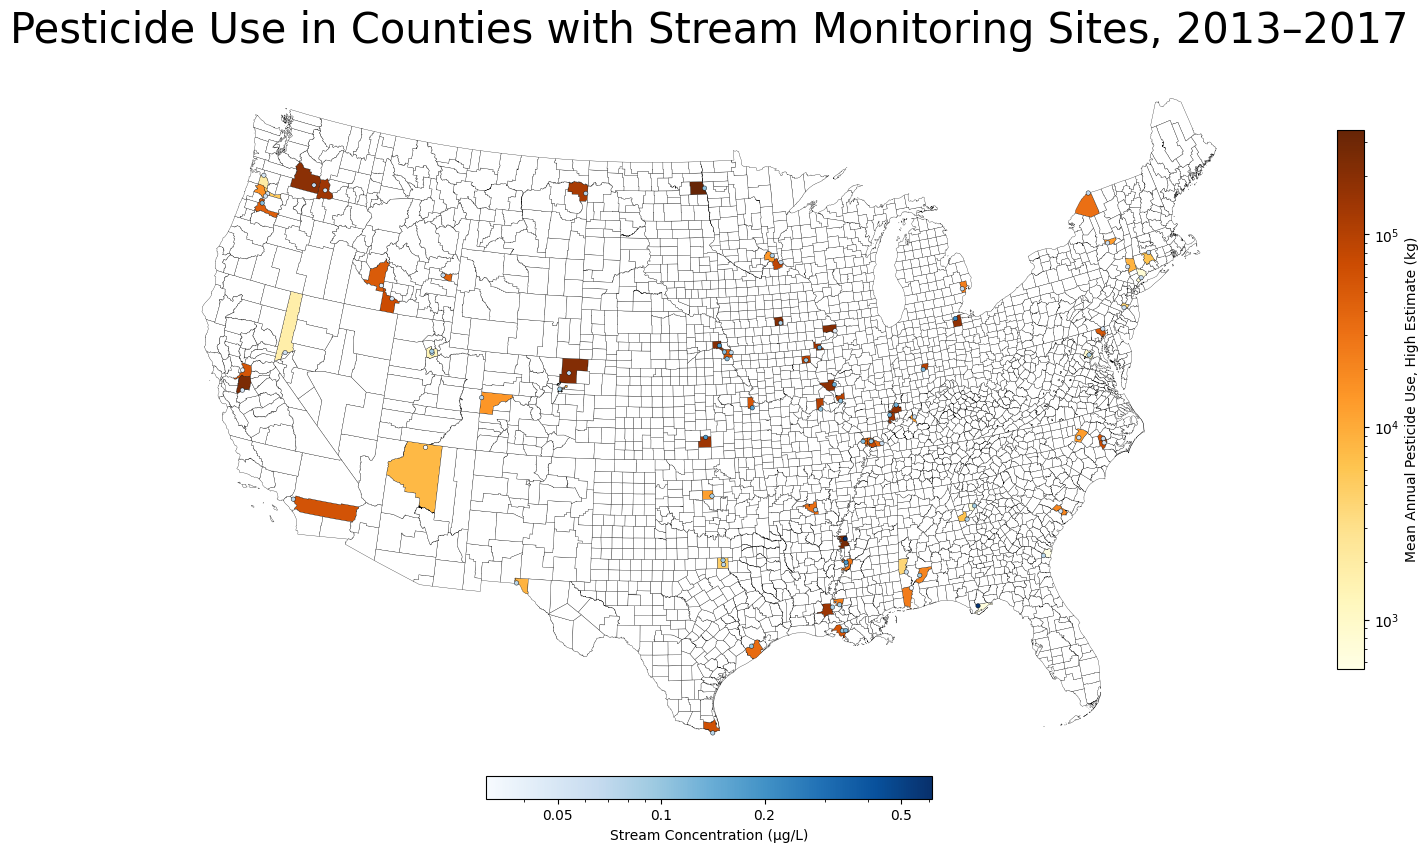

In [76]:
conc_col = 'mean_concentration_water_x'

ax = map_df.plot(
    column='pest_kg', cmap='YlOrBr', norm=LogNorm(),
    edgecolor='black', linewidth=0.2, missing_kwds={'color': 'white'},
    legend=True, legend_kwds={'label': 'Mean Annual Pesticide Use, High Estimate (kg)', 'shrink': 0.5},
    figsize=(18, 14),
)

sites.sort_values(conc_col).plot(
    ax=ax, column=conc_col, cmap='Blues', norm=LogNorm(),
    edgecolor='black', linewidth=0.3, markersize=10, zorder=5,
    legend=True, legend_kwds={'label': 'Stream Concentration (µg/L)', 'shrink': 0.4,
                              'orientation': 'horizontal', 'pad': 0.01,
                              'ticks': [0.05, 0.1, 0.2, 0.5], 'format': '%g'},
)

ax.set_title('Pesticide Use in Counties with Stream Monitoring Sites, 2013–2017', fontsize=30)
ax.axis('off')

 The point of this map was to see where the counties we are doing data analysis for are located. It was also to see where water samples are actually collected in the county.

# Tables

In [41]:
overview = pd.DataFrame({
    'Value': [
        len(pest_water_use),
        pest_water_use['site_id'].nunique(),
        pest_water_use['county_fips'].nunique(),
        pest_water_use['COMPOUND'].nunique(),
        f"{pest_water_use['Water_Year'].min()}–{pest_water_use['Water_Year'].max()}",
    ]
}, index=['Water samples', 'Monitoring sites', 'Counties', 'Pesticides', 'Years'])

stats_tbl = pd.DataFrame({
    'Water concentration (µg/L)': pest_water_use['Result_Value_ug_L'].describe(),
    'County use, high est. (kg)': pest_water_use['EPEST_HIGH_KG'].describe(),
}).rename(index={'count': 'n', '50%': 'median'}).round(3)

display(overview)
display(stats_tbl)

,Value
Water samples,176787
Monitoring sites,79
Counties,74
Pesticides,49
Years,2013–2017


,Water concentration (µg/L),"County use, high est. (kg)"
n,176787.000,176787.000
mean,0.098,2434.465
std,0.734,11833.299
min,0.000,0.000
25%,0.004,13.300
median,0.006,121.700
75%,0.020,782.900
max,137.000,363155.000


In [42]:
by_compound = (
    pest_water_use.groupby('COMPOUND')
    .agg(
        samples=('Result_Value_ug_L', 'size'),
        sites=('site_id', 'nunique'),
        median_conc_ugL=('Result_Value_ug_L', 'median'),
        max_conc_ugL=('Result_Value_ug_L', 'max'),
    )
    .join(
        pest_water_use.groupby('COMPOUND')['EPEST_HIGH_KG']
        .agg(median_use_kg='median', max_use_kg='max')
    )
    .sort_values('samples', ascending=False)
    .round(3)
)

by_compound

,samples,sites,median_conc_ugL,max_conc_ugL,median_use_kg,max_use_kg
COMPOUND,,,,,,
DICAMBA,6429,79,0.500,16.600,349.4,29115.5
PYRACLOSTROBIN,6399,78,0.003,0.389,183.9,5185.3
TRIFLOXYSTROBIN,6262,77,0.002,0.110,73.0,3012.6
IMIDACLOPRID,6256,78,0.016,0.693,68.8,12062.4
CHLORPYRIFOS,6213,77,0.004,0.066,508.6,46106.4
AZOXYSTROBIN,6199,78,0.003,2.910,193.3,6647.5
ATRAZINE,6130,78,0.020,33.000,2877.7,79200.2
"2,4-D",6094,79,0.062,17.900,3473.2,90817.3
PROPICONAZOLE,5682,78,0.006,1.670,128.4,4015.0


### Analysis

In [43]:
result = stats.linregress(reg_df_avg['log_mean_pesticide_use'], reg_df_avg['log_mean_concentration_water'])

pd.Series({
    'slope': result.slope,
    'intercept': result.intercept,
    'R²': result.rvalue**2,
    'p-value': result.pvalue,
}).round(5)

slope        0.21109
intercept   -2.28161
R²           0.13747
p-value      0.00000
dtype: float64

# Pesticide Categories Analysis

### Data Collection

In [44]:
# retrieve pesticide group website

url = "https://www.bcpcpesticidecompendium.org/class_pesticides.html"
response = requests.get(url)
response.raise_for_status()

webpage = BeautifulSoup(response.text, "html.parser")
type(webpage)
if webpage.title:
    print(webpage.title.get_text(strip = True))
else: print("No page title")

Pesticide classification


In [45]:
# herbicide
url = "https://www.bcpcpesticidecompendium.org/class_herbicides.html"
response = requests.get(url)
response.raise_for_status()

webpage = BeautifulSoup(response.text, "html.parser")
type(webpage)
if webpage.title:
    print(webpage.title.get_text(strip = True))
else: print("No page title")

herb = [entry.get_text(strip = True) for entry in webpage.select("li a") if entry.get_text(strip = True)]
herb

Classification of herbicides


['pelargonic acid',
 'diphenamid',
 'naproanilide',
 'napropamide',
 'napropamide-M',
 'chloranocryl',
 'cisanilide',
 'cypromid',
 'erlujixiancaoan',
 'etobenzanid',
 'monalide',
 'pentanochlor',
 'propanil',
 'dimepyrolimet',
 'tetflupyrolimet',
 'benzoylprop',
 'flamprop',
 'flamprop-M',
 'cafenstrole',
 'fentrazamide',
 'ipfencarbazone',
 'benzipram',
 'isoxaben',
 'propyzamide',
 'tebutam',
 'acetochlor',
 'alachlor',
 'allidochlor',
 'amidochlor',
 'butachlor',
 'butenachlor',
 'CDEA',
 'delachlor',
 'diethatyl',
 'dimethachlor',
 'dimethenamid',
 'dimethenamid-P',
 'ethachlor',
 'ethaprochlor',
 'metazachlor',
 'metolachlor',
 'S-metolachlor',
 'pethoxamid',
 'pretilachlor',
 'propachlor',
 'propisochlor',
 'prynachlor',
 'terbuchlor',
 'thenylchlor',
 'xylachlor',
 'quinonamid',
 'benzofluor',
 'pyrimisulfan',
 'triafamone',
 'dimesulfazet',
 'mefluidide',
 'perfluidone',
 'diflufenzopyr',
 'naptalam',
 'cambendichlor',
 'chloramben',
 'chlorthal',
 'dicamba',
 '2,3,6-TBA',
 't

In [46]:
def get_pesticides(pesticide_type):
    url = f"https://www.bcpcpesticidecompendium.org/class_{pesticide_type}.html"
    response = requests.get(url)
    response.raise_for_status()
    the_website = BeautifulSoup(response.text, "html.parser")

    pesticides = [entry.get_text(strip = True) for entry in the_website.select("li a") if entry.get_text(strip = True)]

    return pesticides

In [47]:
# use function for different pesticide categories

# pest_types = ["bactericides", "herbicides", "fungicides", "rodenticides", "nematicides"]
# could be made into a loop

bactericides = get_pesticides("bactericides")
herbicides = get_pesticides("herbicides")
fungicides = get_pesticides("fungicides")
rodenticides = get_pesticides("rodenticides")
nematicides = get_pesticides("nematicides")

In [48]:
# create dataframe to match to pesticide concentrations

categories = {
    "bactericides" : bactericides,
    "herbicides" : herbicides,
    "fungicides" : fungicides,
    "rodenticides" : rodenticides,
    "nematicides" : nematicides
}

pest_categories = pd.DataFrame(
    [(compound, category)
     for category, compounds in categories.items()
     for compound in compounds],
     columns = ["Compound", "Pesticide Category"]
)

pest_categories.head()

,Compound,Pesticide Category
0,pelargonic acid,herbicides
1,diphenamid,herbicides
2,naproanilide,herbicides
3,napropamide,herbicides
4,napropamide-M,herbicides


### Categorize

In [49]:
#cleaning columns 
pest_water_use = pest_water_use.loc[:,['Pesticide_Name', 'Water_Year', 'Result_Value_ug_L', 'site_id', 'Drainage_area_km2','county_fips','EPEST_HIGH_KG','COMPOUND','geometry']]
pest_water_use["COMPOUND"].unique()

<ArrowStringArray>
[             '2,4-D',           'ACEPHATE',         'ACETOCHLOR',
           'ATRAZINE',       'AZOXYSTROBIN',           'BROMACIL',
         'BROMOXYNIL',           'CARBARYL',       'CHLORPYRIFOS',
           'DIAZINON',            'DICAMBA',        'DICROTOPHOS',
      'DIFLUBENZURON',       'DIMETHENAMID',         'DIMETHOATE',
             'DIURON',        'ETHOPROPHOS',          'ETOXAZOLE',
           'FIPRONIL',        'FLUOMETURON',         'GLYPHOSATE',
         'HEXAZINONE',        'IMAZETHAPYR',       'IMIDACLOPRID',
            'LINURON',          'MALATHION',          'METALAXYL',
        'METCONAZOLE',           'METHOMYL',    'METHOXYFENOZIDE',
        'METOLACHLOR',         'METRIBUZIN',       'MYCLOBUTANIL',
           'ORYZALIN', 'PIPERONYL BUTOXIDE',           'PROMETON',
          'PROPAZINE',      'PROPICONAZOLE',           'PROPOXUR',
     'PYRACLOSTROBIN',           'SIMAZINE',      'SULFENTRAZONE',
       'TEBUCONAZOLE',        'TEBUTHIURON'

In [50]:
print(pest_categories["Compound"].unique())
#slight problem the pest key has different compounds per category than what compounds data actually contains
# alternative is to either look for another online list, or create a dataset specifically for the 49 pesticides used

search = pest_categories[pest_categories["Compound"] == "Tetraconazole"]
search.head()

<ArrowStringArray>
[ 'pelargonic acid',       'diphenamid',     'naproanilide',
      'napropamide',    'napropamide-M',     'chloranocryl',
       'cisanilide',         'cypromid',  'erlujixiancaoan',
      'etobenzanid',
 ...
      'fosthiazate',       'fosthietan',        'imicyafos',
       'diamidafos',         'xylenols',       'acetoprole',
 'fluazaindolizine',      'benclothiaz',      'fenargimine',
       'tioxazafen']
Length: 1138, dtype: str


,Compound,Pesticide Category


### Joining Dataset to Pesticide Key

In [51]:
# import pesticide category key and join to pest_water_use
pest_cat = pd.read_csv(raw_fldr/'PestCategoryKey.csv')

#left join between pest_water_use and pest_categories using compound column 
pest_water_categorized = pd.merge(
    pest_water_use_avg,
    pest_cat,
    left_on = "Pesticide_Name",
    right_on = "Compound",
    how = "left"
).drop(columns = "Compound")


missing = pest_water_categorized.isna().mean().sort_values(ascending = False) * 100
missing.head()

# don't know why there is missing % in pest_category when i made it by hand with the pesticide names oh well

Pest_Category               0.166634
Pesticide_Name              0.000000
Water_Year                  0.000000
site_id                     0.000000
mean_concentration_water    0.000000
dtype: float64

In [52]:
pest_water_categorized.head()

,Pesticide_Name,Water_Year,site_id,mean_concentration_water,mean_pesticide_use,log_mean_pesticide_use,log_mean_concentration_water,Pest_Category
0,"2,4-D",2013,01184000,0.128033,362.3,2.559068,-0.892677,herbicide
1,"2,4-D",2013,01209710,0.075609,80.7,1.906874,-1.121428,herbicide
2,"2,4-D",2013,01349150,0.063613,515.2,2.711976,-1.196458,herbicide
3,"2,4-D",2013,01372043,0.052507,742.3,2.870579,-1.279782,herbicide
4,"2,4-D",2013,01463500,0.061000,419.3,2.622525,-1.214670,herbicide


In [53]:
pest_water_categorized["mean_concentration_water"].describe()

count    10202.000000
mean         0.093596
std          0.386595
min          0.001356
25%          0.004588
50%          0.007529
75%          0.030692
max         13.453625
Name: mean_concentration_water, dtype: float64

In [54]:
pest_water_categorized = (pest_water_categorized
            .replace([np.inf, -np.inf], np.nan)
            .dropna(subset=['log_mean_pesticide_use', 'log_mean_concentration_water']))

In [55]:
# save cleaned data to processed folder
pest_water_categorized.to_csv(processed_fldr/"pest_water_cat.csv", index=False)


### Figures

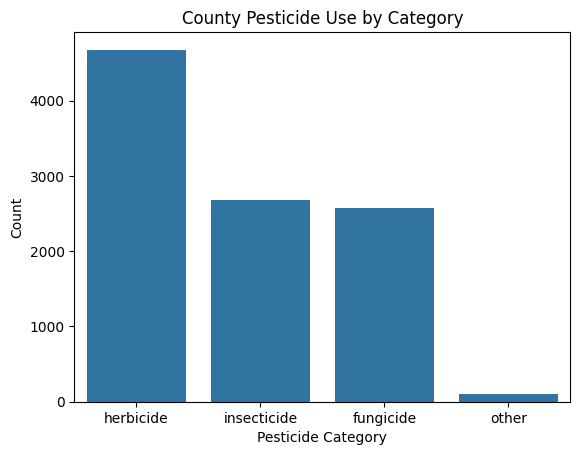

In [56]:
sns.countplot(
    data = pest_water_categorized,
    x = "Pest_Category",
).set(
    title = "County Pesticide Use by Category",
    xlabel = "Pesticide Category",
    ylabel = "Count"
);

# huzzah
# need to average the site location values per year (if there are multiple entries per year per site per pesticide)

County pesticide use by category represents the total range of year in our datasets, 2013-2017. It includes repeats of pesticides across the years. An example interpretation is that across all counties in the dataset, and across all years, a fungicide was applied ~2500 times. It does not indicate the total amount of fungicide applied.

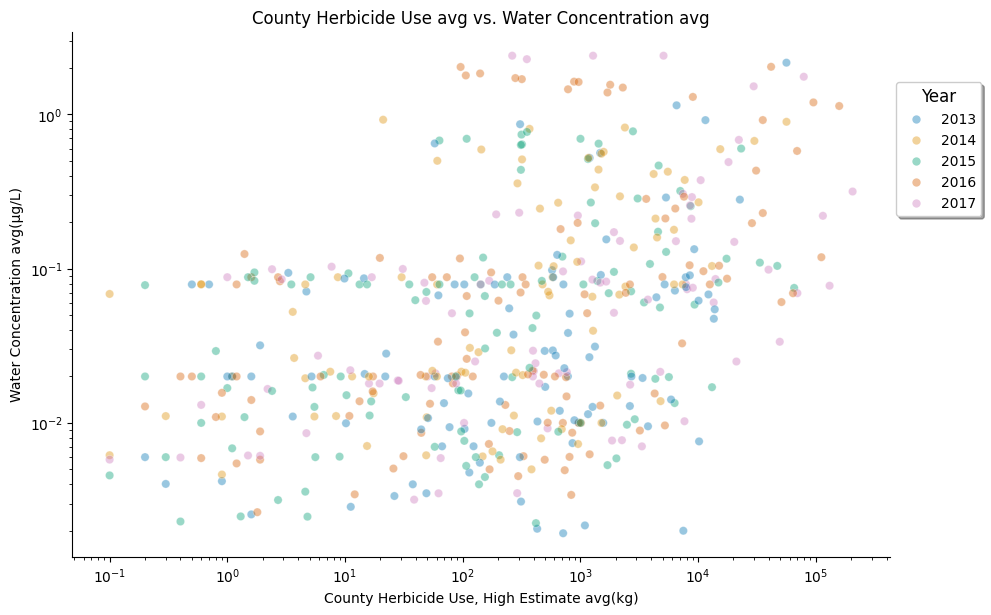

In [57]:
# herbicide only scatterplot

herbicide_df = pest_water_categorized[pest_water_categorized["Pest_Category"] == "herbicide"].copy()

herb_plot = herbicide_df.sample(500, random_state = 1)

g = sns.relplot(
    data = herb_plot,
    x ='mean_pesticide_use',
    y ='mean_concentration_water',
    hue ='Water_Year',
    kind ='scatter',
    alpha = 0.4,
    palette ='colorblind',
    height = 6,
    aspect = 1.5
).set(
    title ='County Herbicide Use avg vs. Water Concentration avg',
    xlabel ='County Herbicide Use, High Estimate avg(kg)',
    ylabel ='Water Concentration avg(µg/L)',
    xscale ='log',
    yscale ='log'
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor = (1, 0.9),
    title = 'Year',
    title_fontsize = 12,
    shadow = True,
    frameon = True
);

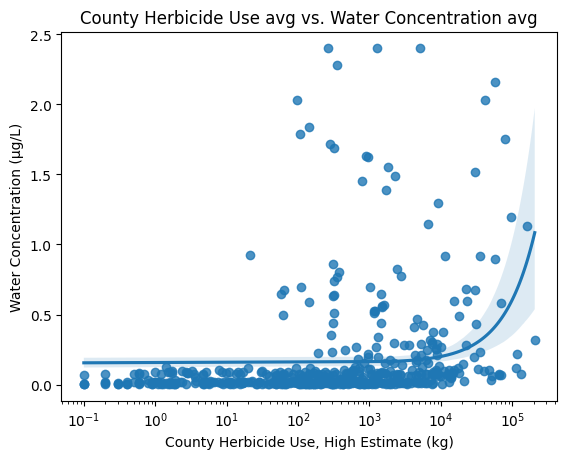

In [58]:
# same as scatterplot, but with linear regression

g = sns.regplot(
    data = herb_plot,
    x ='mean_pesticide_use',
    y ='mean_concentration_water',
).set(
    title ='County Herbicide Use avg vs. Water Concentration avg',
    xlabel ='County Herbicide Use, High Estimate (kg)',
    ylabel ='Water Concentration (µg/L)',
    xscale ='log'
);

#logging may be necessary

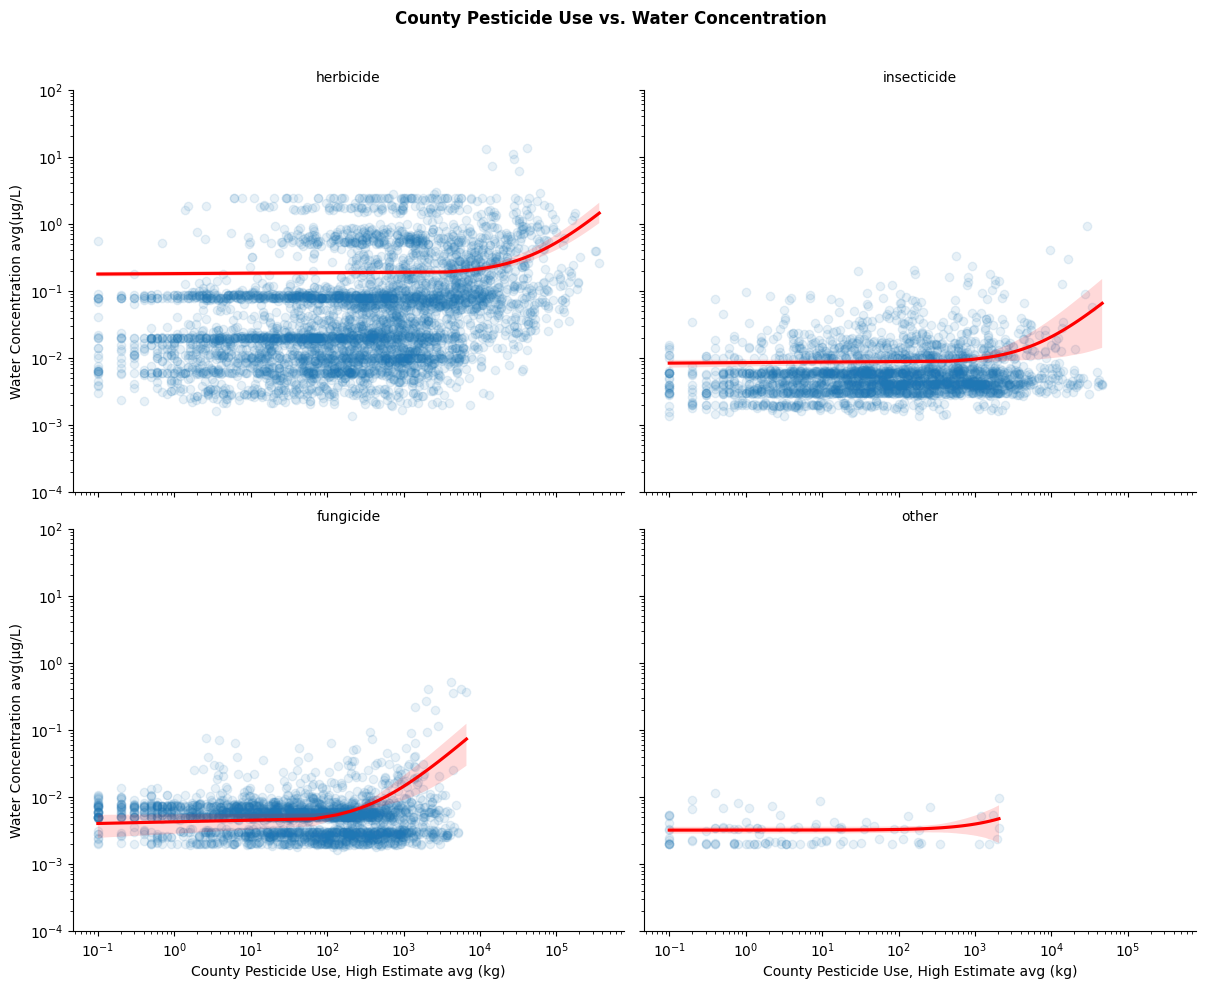

In [59]:
# linear regression of each pesticide category, side by side
g = sns.lmplot(
    data = pest_water_categorized,
    x ='mean_pesticide_use',
    y ='mean_concentration_water',
   # hue = "Pest_Category",
    col = "Pest_Category",
    col_wrap = 2,
    height = 5,
    aspect = 1.2,
    scatter_kws = {"alpha" : 0.1},
    line_kws = {"color" : "red"}
)

g.set(
    xlabel ='County Pesticide Use, High Estimate avg (kg)',
    ylabel ='Water Concentration avg(µg/L)',
    xscale ='log',
    yscale = 'log',
    ylim = (0.0001, 100)
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "County Pesticide Use vs. Water Concentration",
    fontweight = "bold"
)

g.figure.subplots_adjust(
    top = 0.90
)


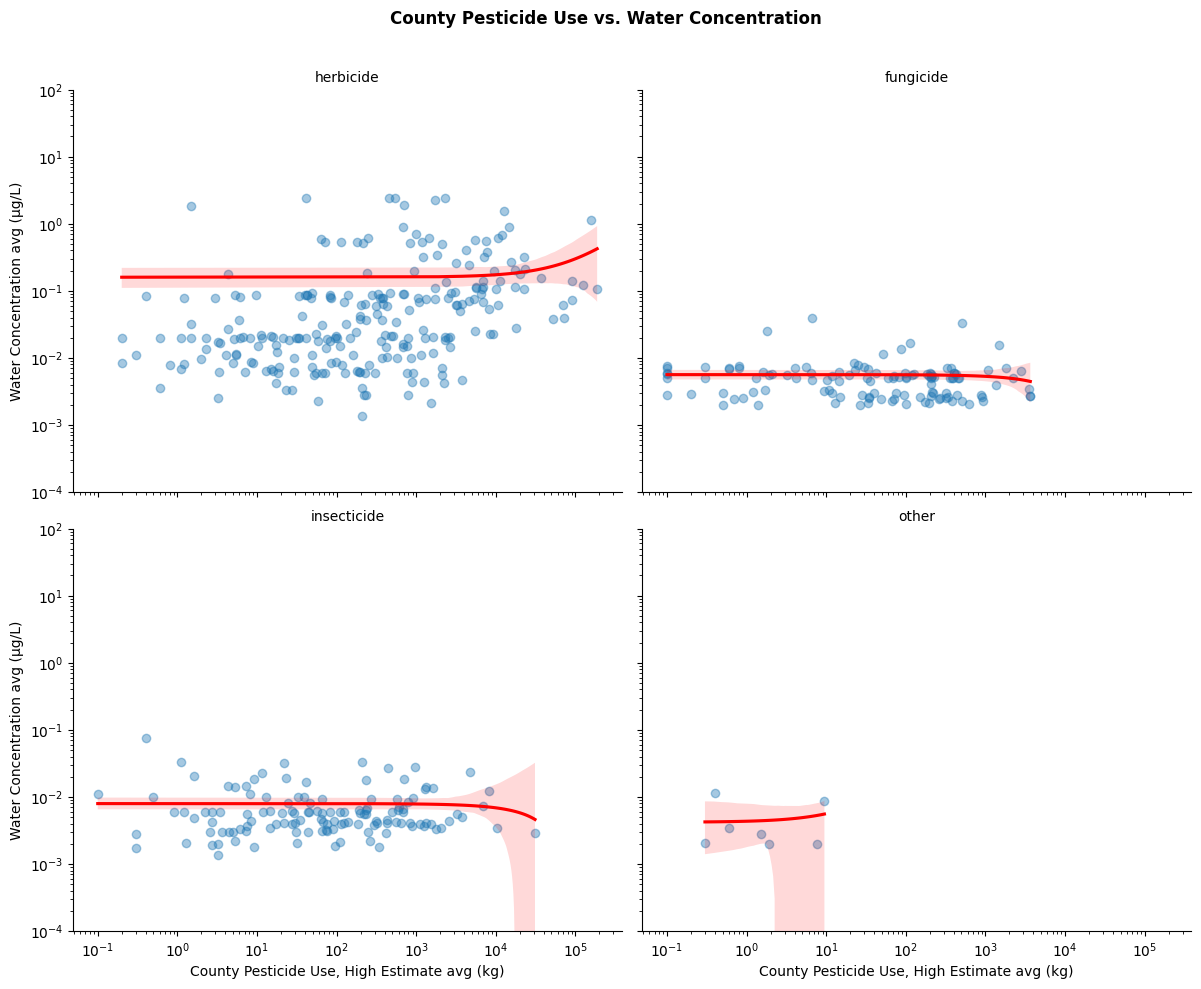

In [60]:
# same plot but with random sample of 500
pest_water_categorized_plot = pest_water_categorized.sample(500, random_state = 1)

g = sns.lmplot(
    data = pest_water_categorized_plot,
    x ='mean_pesticide_use',
    y ='mean_concentration_water',
   # hue = "Pest_Category",
    col = "Pest_Category",
    col_wrap = 2,
    height = 5,
    aspect = 1.2,
    scatter_kws = {"alpha" : 0.4},
    line_kws = {"color" : "red"}
)

g.set(
    xlabel ='County Pesticide Use, High Estimate avg (kg)',
    ylabel ='Water Concentration avg (µg/L)',
    xscale ='log',
    yscale ='log',
    ylim = (0.0001, 100)
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "County Pesticide Use vs. Water Concentration",
    fontweight = "bold"
)

g.figure.subplots_adjust(
    top = 0.90
)

### Logged Data 

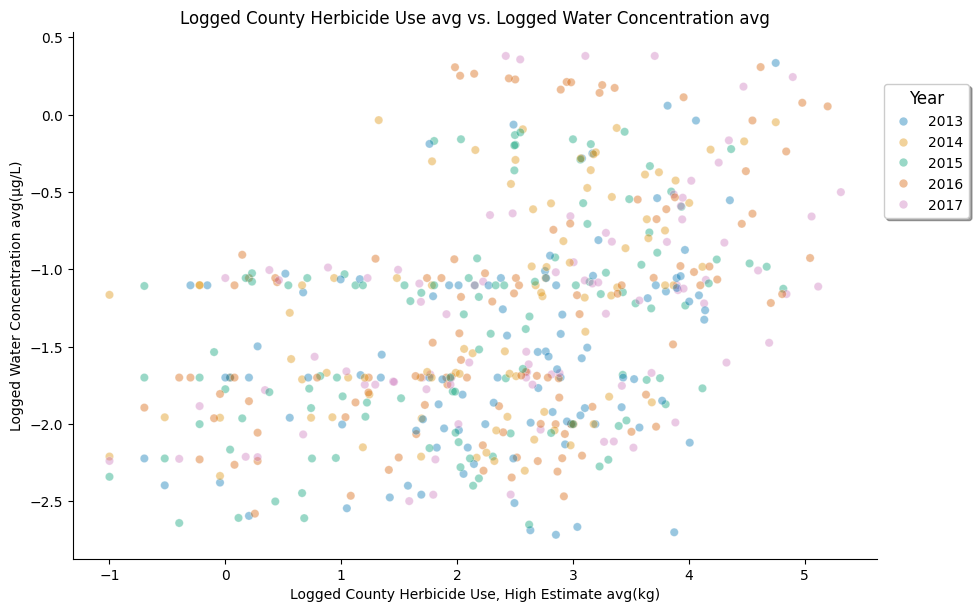

In [61]:
# herbicide only scatterplot

herbicide_df = pest_water_categorized[pest_water_categorized["Pest_Category"] == "herbicide"].copy()

herb_plot = herbicide_df.sample(500, random_state = 1)

g = sns.relplot(
    data = herb_plot,
    x ='log_mean_pesticide_use',
    y ='log_mean_concentration_water',
    hue ='Water_Year',
    kind ='scatter',
    alpha = 0.4,
    palette ='colorblind',
    height = 6,
    aspect = 1.5
).set(
    title ='Logged County Herbicide Use avg vs. Logged Water Concentration avg',
    xlabel ='Logged County Herbicide Use, High Estimate avg(kg)',
    ylabel ='Logged Water Concentration avg(µg/L)'
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor = (1, 0.9),
    title = 'Year',
    title_fontsize = 12,
    shadow = True,
    frameon = True
);

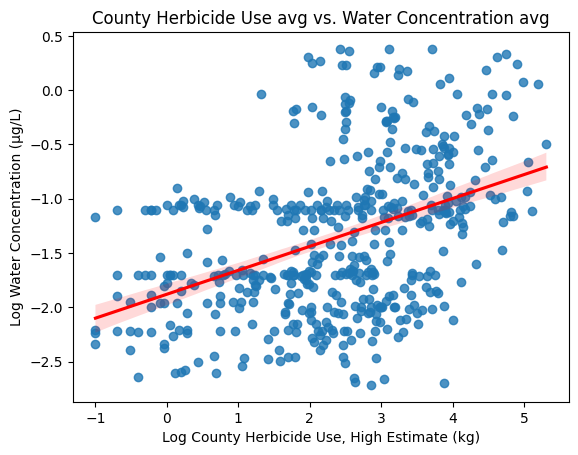

In [62]:
# same as scatterplot, but with linear regression
herb_fit = (herb_plot
            .replace([np.inf, -np.inf], np.nan)
            .dropna(subset=['log_mean_pesticide_use', 'log_mean_concentration_water']))

ax = sns.regplot(
    data=herb_fit,
    x='log_mean_pesticide_use',
    y='log_mean_concentration_water',
    line_kws={'color': 'red'}
)
ax.set(
    title='County Herbicide Use avg vs. Water Concentration avg',
    xlabel='Log County Herbicide Use, High Estimate (kg)',
    ylabel='Log Water Concentration (µg/L)'
);



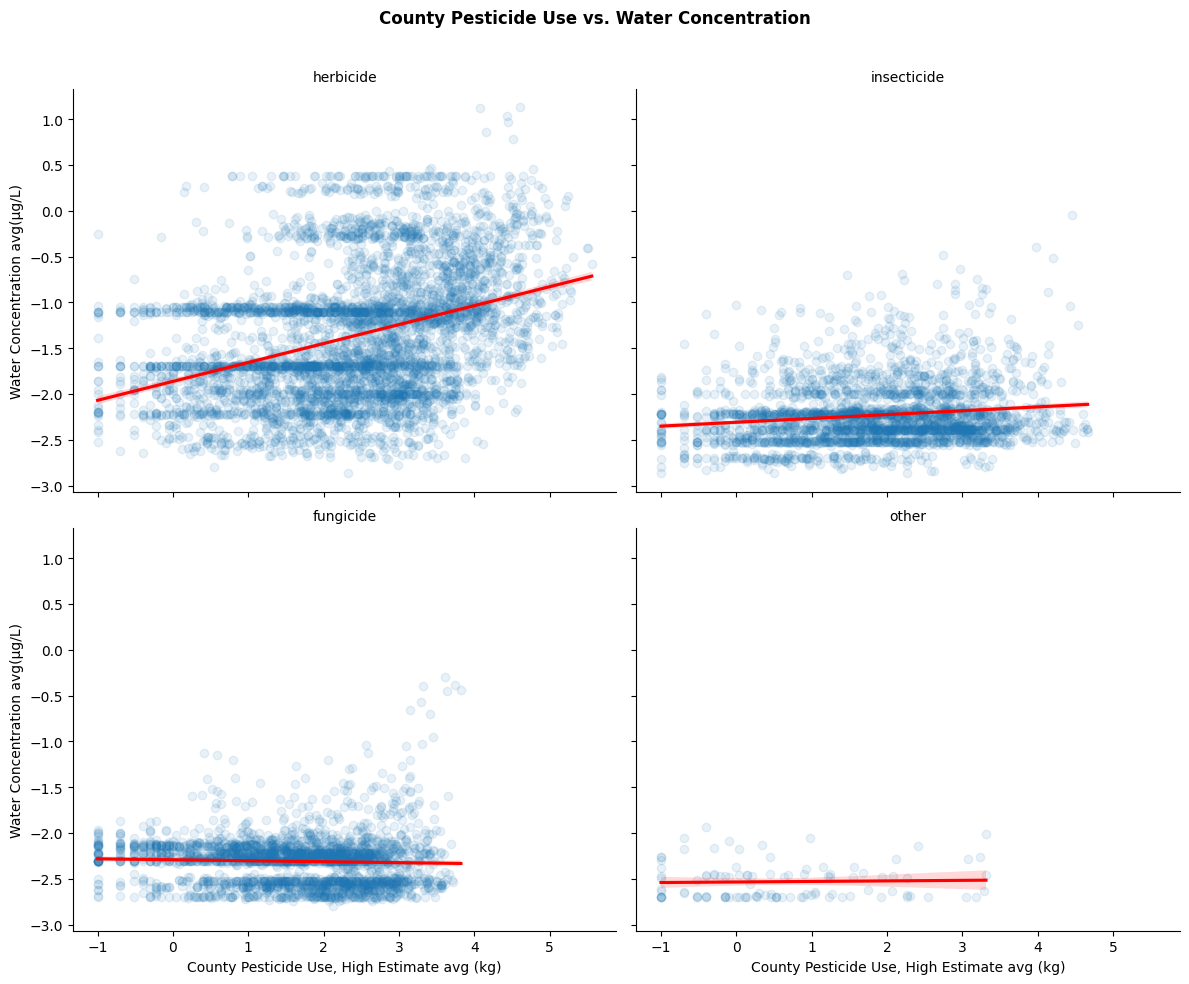

In [63]:
# linear regression of each pesticide category, side by side
g = sns.lmplot(
    data = pest_water_categorized,
    x ='log_mean_pesticide_use',
    y ='log_mean_concentration_water',
   # hue = "Pest_Category",
    col = "Pest_Category",
    col_wrap = 2,
    height = 5,
    aspect = 1.2,
    scatter_kws = {"alpha" : 0.1},
    line_kws = {"color" : "red"}
)

g.set(
    xlabel ='County Pesticide Use, High Estimate avg (kg)',
    ylabel ='Water Concentration avg(µg/L)'
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "County Pesticide Use vs. Water Concentration",
    fontweight = "bold"
)

g.figure.subplots_adjust(
    top = 0.90
)

In [64]:
# validation for herbicide regression plot
result = stats.linregress(herb_fit['log_mean_pesticide_use'], herb_fit['log_mean_concentration_water'])

pd.Series({
    'slope': result.slope,
    'intercept': result.intercept,
    'R²': result.rvalue**2,
    'p-value': result.pvalue,
}).round(5)

slope        0.22040
intercept   -1.87981
R²           0.17671
p-value      0.00000
dtype: float64

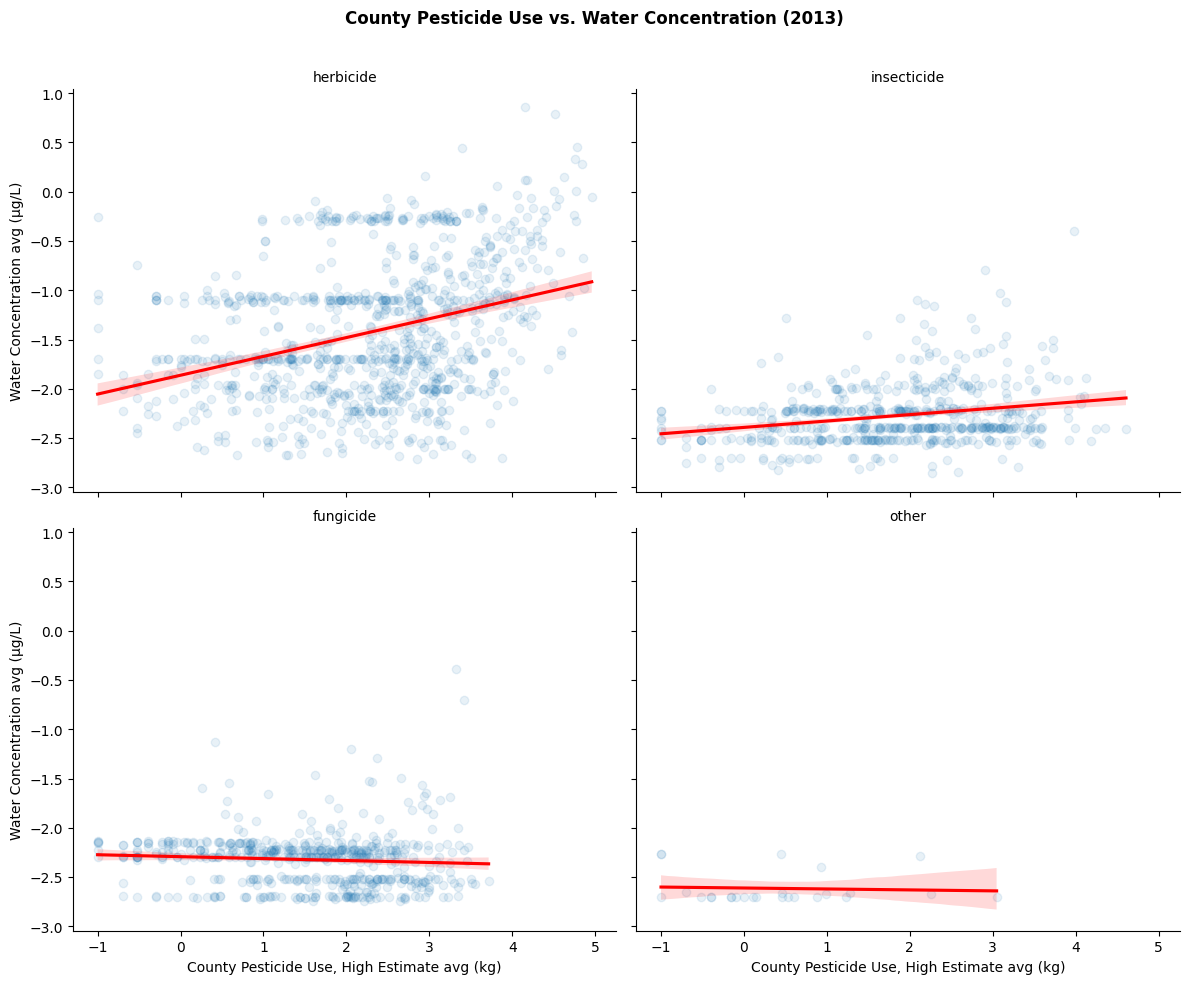

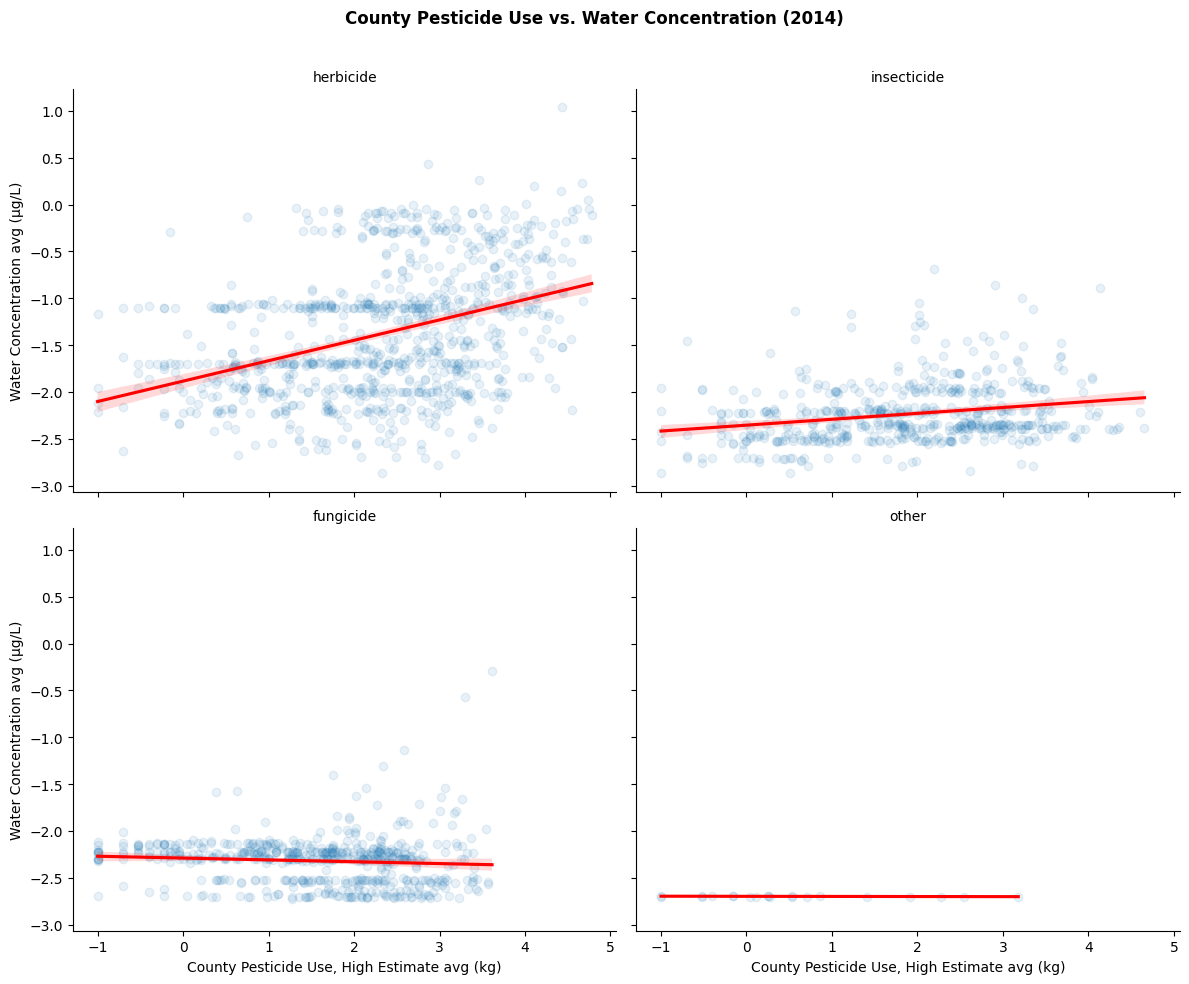

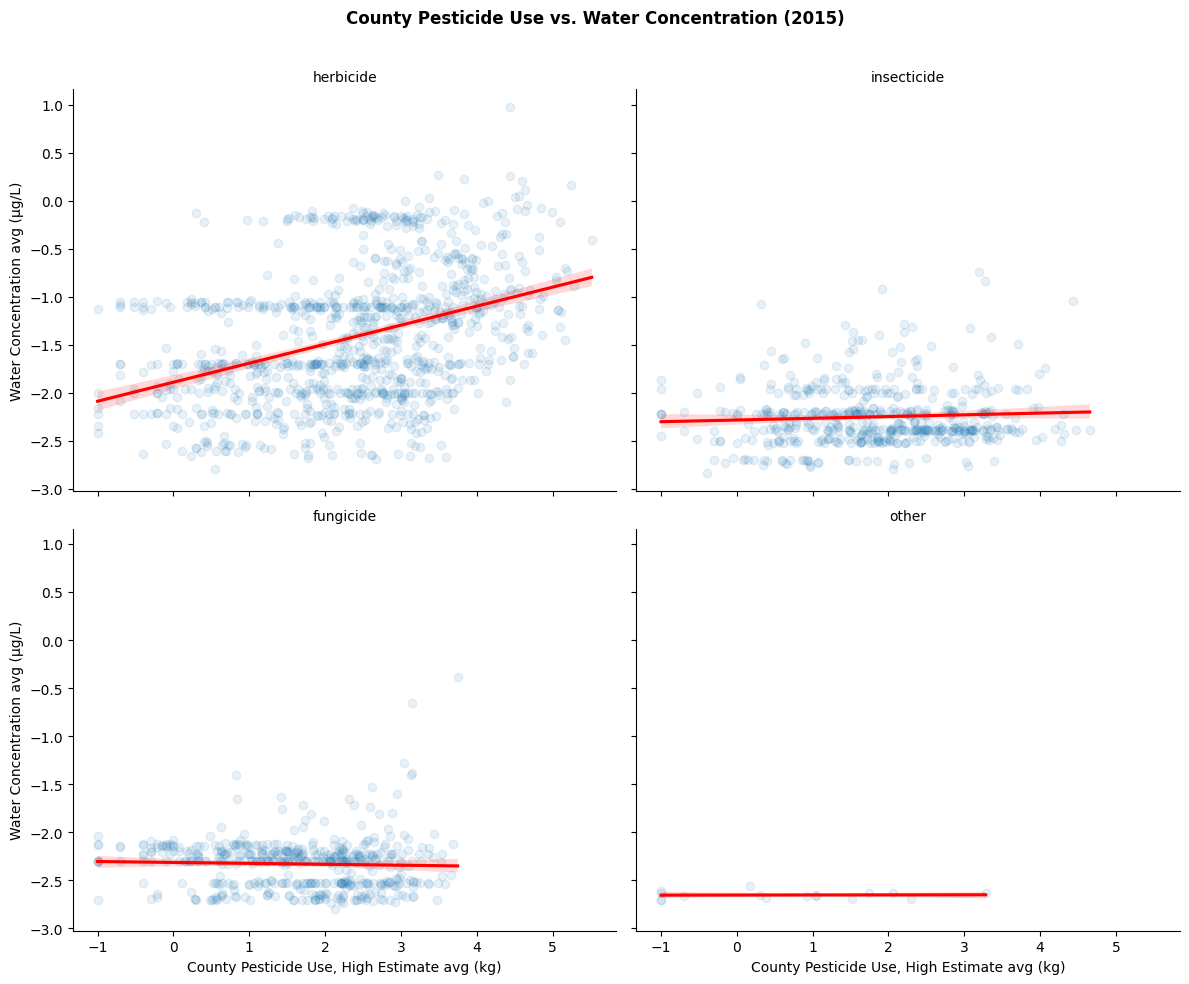

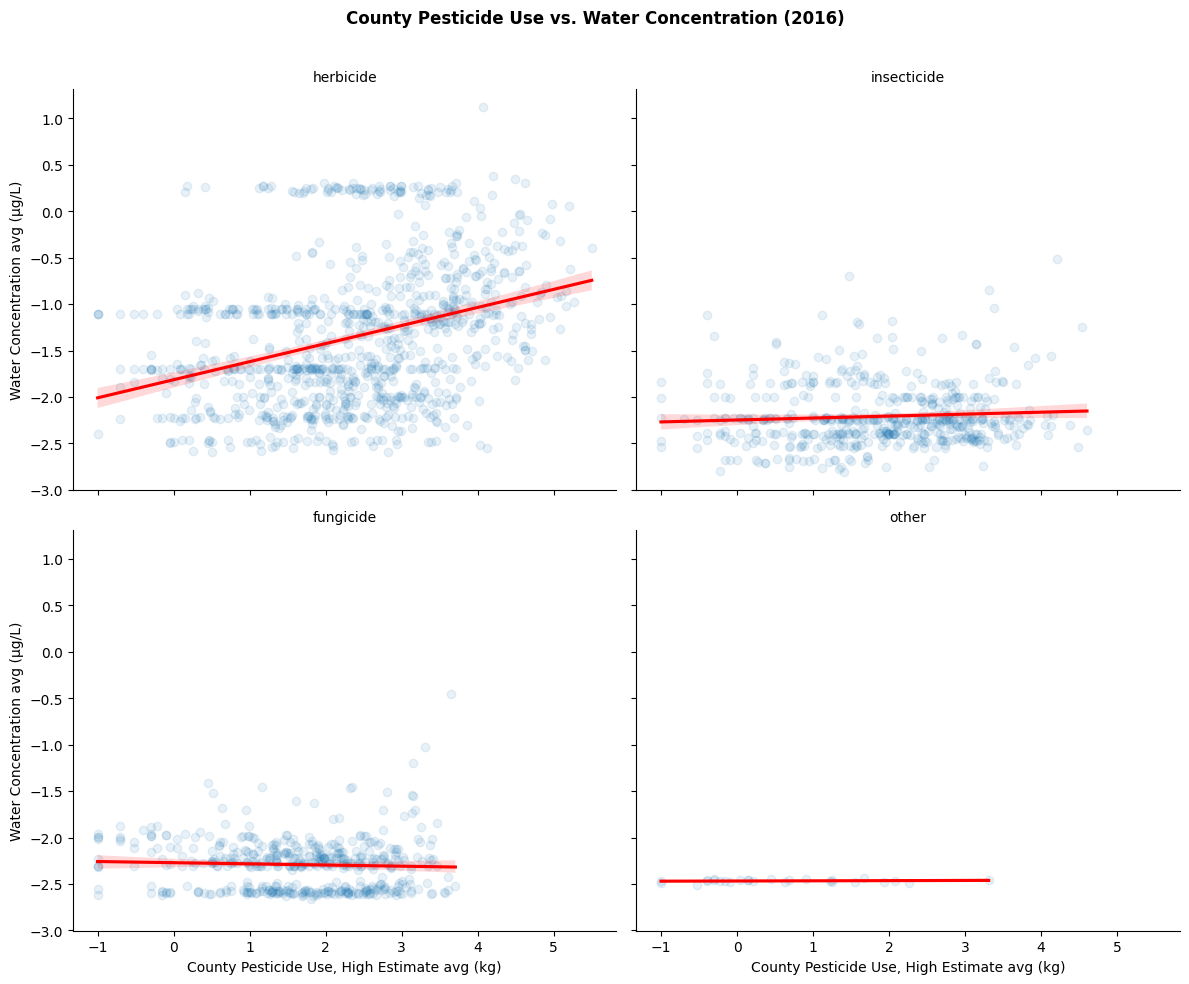

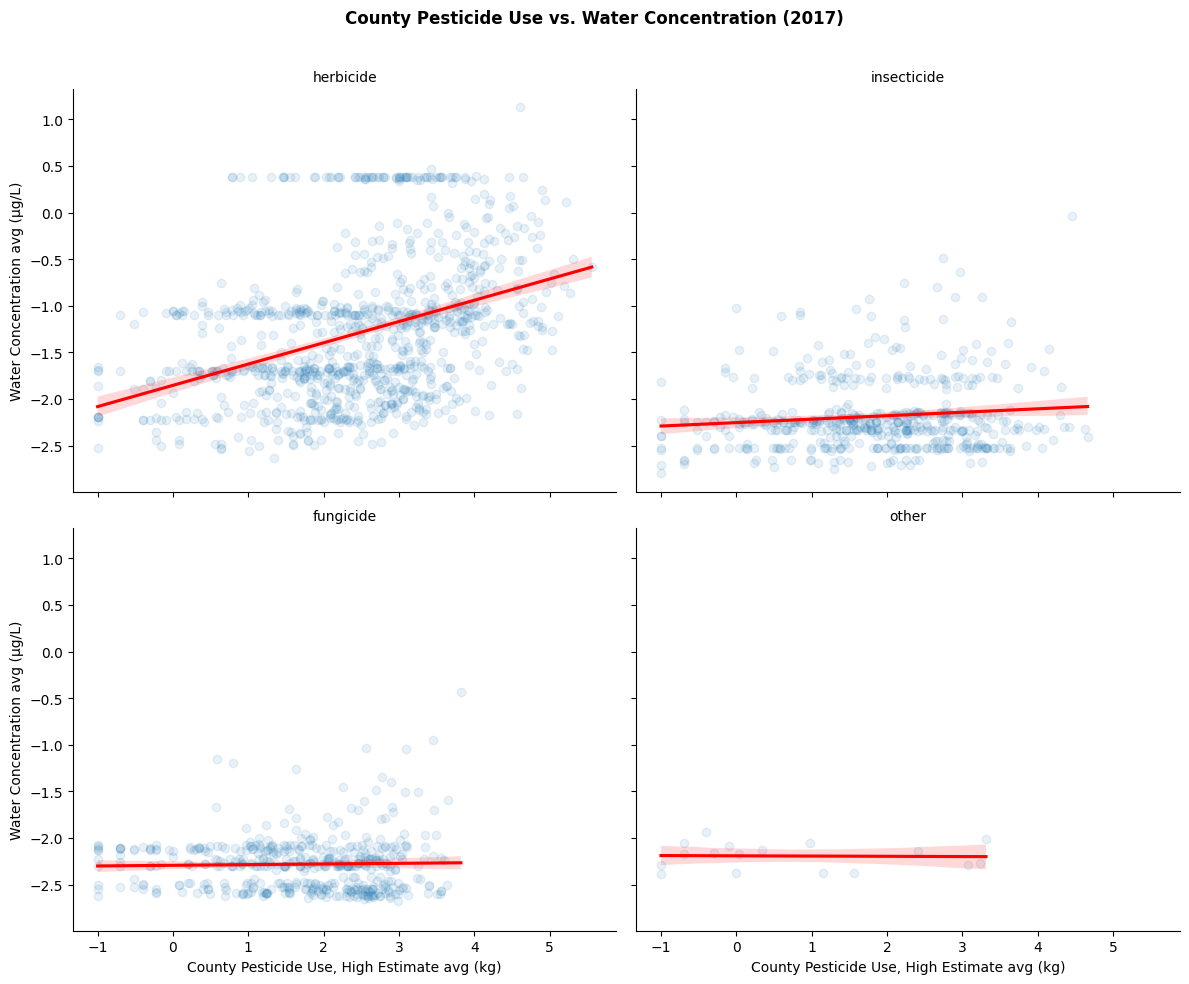

In [65]:
# Replot this for each individual year
for year in range(2013, 2018):

    year_data = pest_water_categorized[
        pest_water_categorized['Water_Year'] == year
    ]

    g = sns.lmplot(
        data=year_data,
        x='log_mean_pesticide_use',
        y='log_mean_concentration_water',
        col='Pest_Category',
        col_wrap=2,
        height=5,
        aspect=1.2,
        scatter_kws={"alpha": 0.1},
        line_kws={"color": "red"}
    )

    g.set(
        xlabel='County Pesticide Use, High Estimate avg (kg)',
        ylabel='Water Concentration avg (µg/L)'
    )

    g.set_titles("{col_name}")

    g.figure.suptitle(
        f"County Pesticide Use vs. Water Concentration ({year})",
        fontweight="bold"
    )

    g.figure.subplots_adjust(top=0.90)

    plt.show()


### Table

In [66]:
category_count = (
    pest_water_categorized.groupby(["Water_Year", "Pest_Category"])
    .size()
    .reset_index(name = "Count")
)

category_count["Water_Year"] = category_count["Water_Year"].astype("str")

category_count.head(n = 20)

,Water_Year,Pest_Category,Count
0,2013,fungicide,554
1,2013,herbicide,930
2,2013,insecticide,571
3,2013,other,26
4,2014,fungicide,560
5,2014,herbicide,860
6,2014,insecticide,542
7,2014,other,21
8,2015,fungicide,501
9,2015,herbicide,990


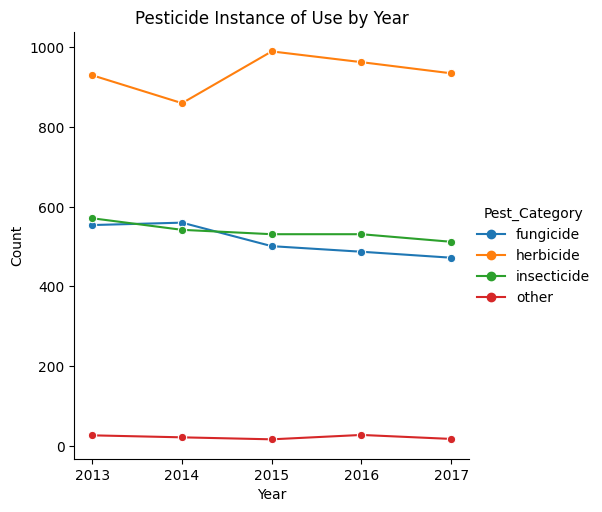

In [67]:
sns.relplot(
    data = category_count,
    x = "Water_Year",
    y = "Count",
    hue = "Pest_Category",
    kind = "line",
    marker = "o"
).set(
    title = "Pesticide Instance of Use by Year",
    xlabel = "Year",
    ylabel = "Count"
);

Brief look at the number of times per year that a reported agricultural pesticide matched with USGS stream water pesticide concentration. This is across all counties in the contiguous US that had pesticide use estimates. 